### correlation of  climate and vegetation against drought indices

ERA5 Tmean files found: 312
Building stacks ...
Computing correlations ...
  SKIP (exists): Precip_SPI1_r.tif
  SKIP (exists): Precip_SPI3_r.tif
  SKIP (exists): Precip_SPI6_r.tif
  SKIP (exists): Precip_SPI12_r.tif
  SKIP (exists): Precip_SPEI1_r.tif
  SKIP (exists): Precip_SPEI3_r.tif
  SKIP (exists): Precip_SPEI6_r.tif
  SKIP (exists): Precip_SPEI12_r.tif
  SKIP (exists): Precip_VCI_r.tif
  SKIP (exists): Precip_TCI_r.tif
  SKIP (exists): Precip_VHI_r.tif
  SKIP (exists): NDVI_SPI1_r.tif
  SKIP (exists): NDVI_SPI3_r.tif
  SKIP (exists): NDVI_SPI6_r.tif
  SKIP (exists): NDVI_SPI12_r.tif
  SKIP (exists): NDVI_SPEI1_r.tif
  SKIP (exists): NDVI_SPEI3_r.tif
  SKIP (exists): NDVI_SPEI6_r.tif
  SKIP (exists): NDVI_SPEI12_r.tif
  SKIP (exists): NDVI_VCI_r.tif
  SKIP (exists): NDVI_TCI_r.tif
  SKIP (exists): NDVI_VHI_r.tif
  SKIP (exists): LST_SPI1_r.tif
  SKIP (exists): LST_SPI3_r.tif
  SKIP (exists): LST_SPI6_r.tif
  SKIP (exists): LST_SPI12_r.tif
  SKIP (exists): LST_SPEI1_r.tif
  SKIP (e

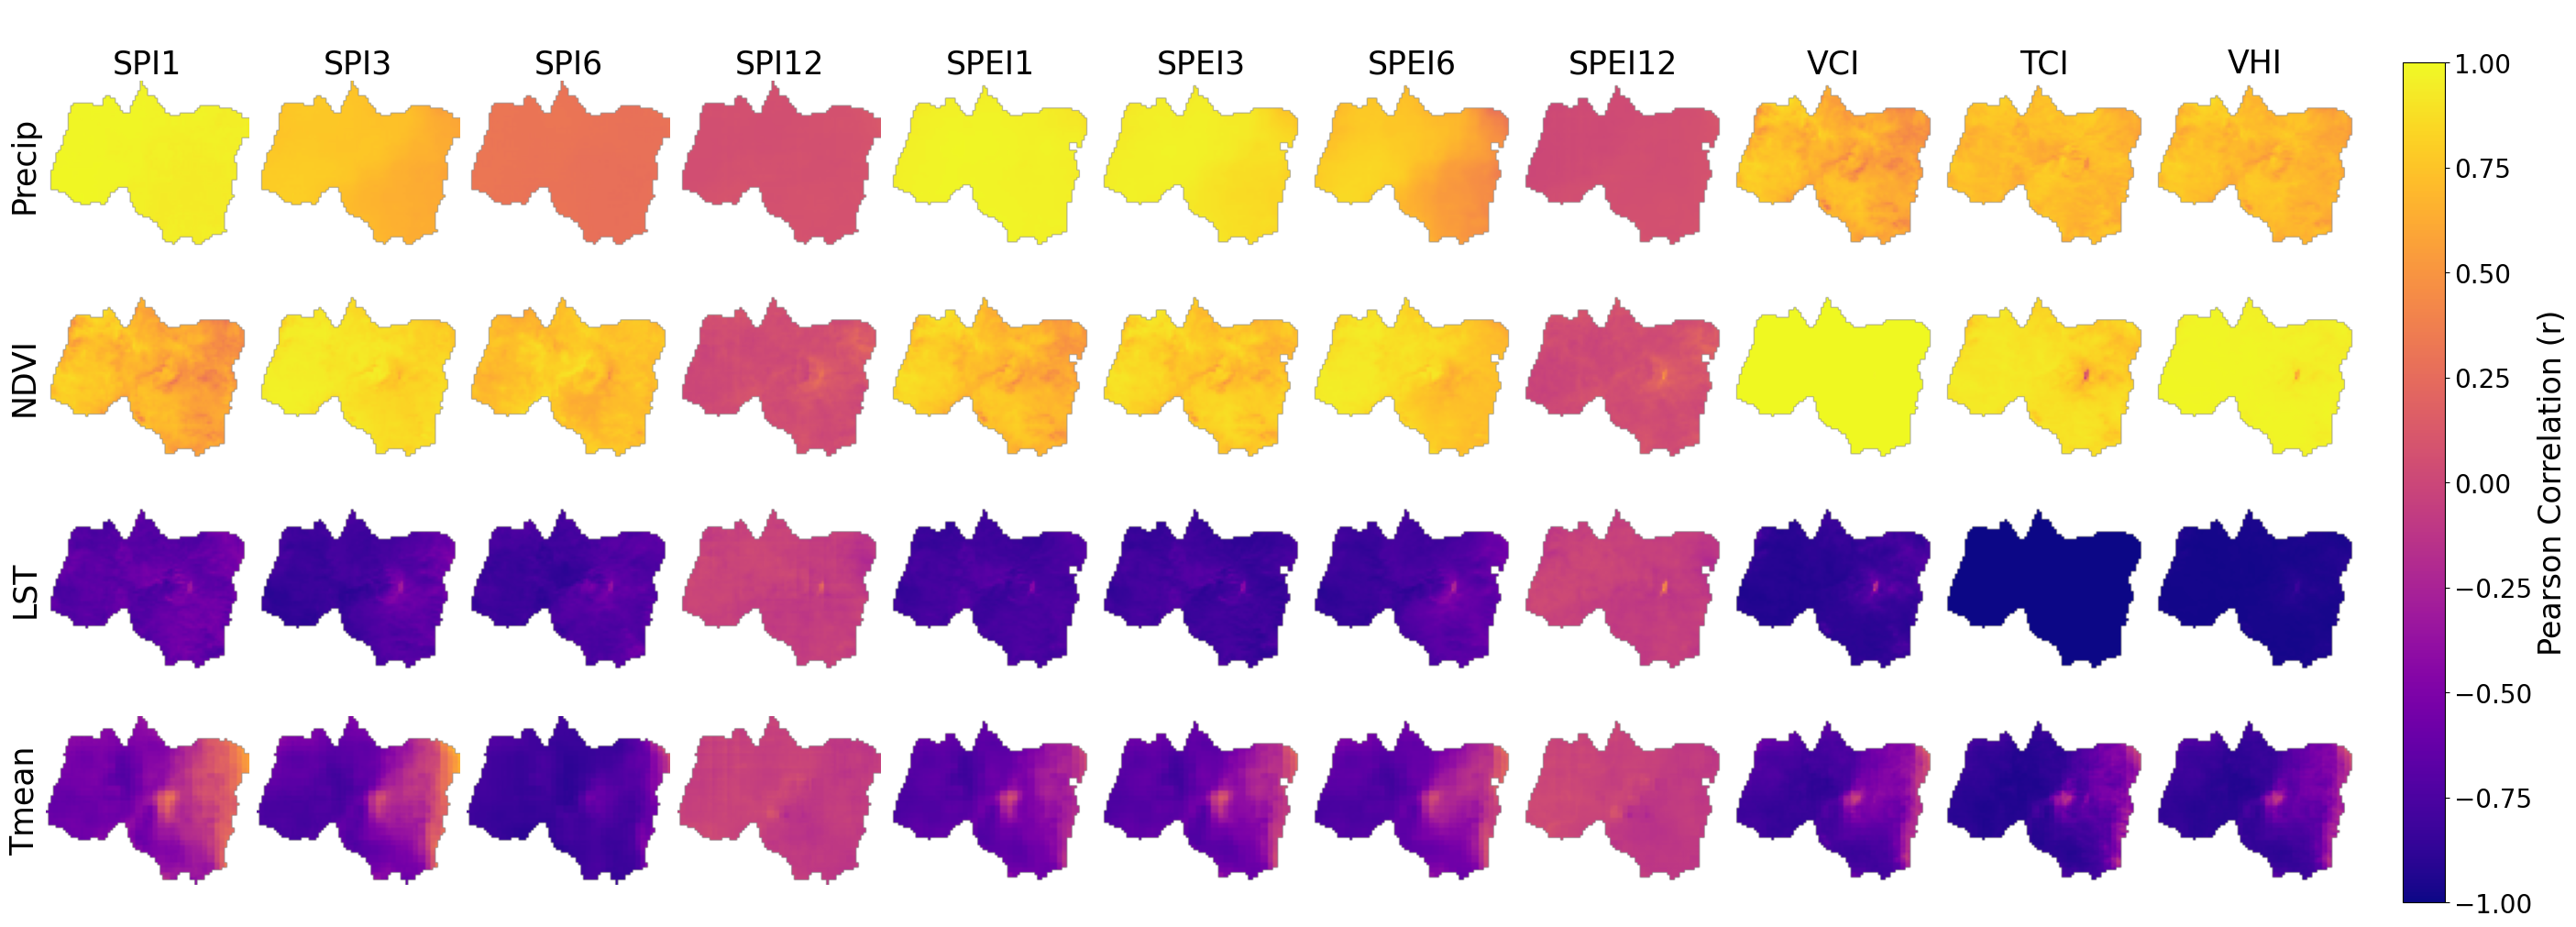

Saved: C:\Users\gerii\Documents\projects\tekeze\ALL_44_CORRELATION_MAPS.png


In [5]:
import os
import re
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"

CHIRPS_DIR = os.path.join(BASE_DIR, "CHIRPS_500m")
NDVI_DIR   = os.path.join(BASE_DIR, "NDVI_outputs")
LST_DIR    = os.path.join(BASE_DIR, "LST")
ERA5_DIR   = os.path.join(BASE_DIR, "ERA5_Tmean")

IND_DIR = os.path.join(BASE_DIR, "indices")

SPI_DIR  = os.path.join(IND_DIR, "SPI")
SPEI_DIR = os.path.join(IND_DIR, "SPEI")

VCI_DIR = os.path.join(IND_DIR, "VCI")
TCI_DIR = os.path.join(IND_DIR, "TCI")
VHI_DIR = os.path.join(IND_DIR, "VHI")

OUT_DIR = os.path.join(BASE_DIR, "Correlation_Maps")
os.makedirs(OUT_DIR, exist_ok=True)

OUT_PNG = os.path.join(BASE_DIR, "ALL_44_CORRELATION_MAPS.png")

# ============================================================
# TIME RANGE
# ============================================================

dates = np.arange("2000-02", "2026-01", dtype="datetime64[M]")
keys  = [str(d).replace("-", "_") for d in dates]

# ============================================================
# GET REFERENCE GRID (SPI1)
# ============================================================

ref_path = os.path.join(SPI_DIR, "SPI1_200002.tif")

with rasterio.open(ref_path) as src:
    ref_shape     = src.shape
    ref_transform = src.transform
    ref_crs       = src.crs
    ref_meta      = src.meta.copy()

rows, cols = ref_shape

# ============================================================
# FUNCTION: READ + RESAMPLE TO SPI GRID
# ============================================================

def read_and_resample(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float32)
        out  = np.empty((rows, cols), dtype=np.float32)
        reproject(
            source        = data,
            destination   = out,
            src_transform = src.transform,
            src_crs       = src.crs,
            dst_transform = ref_transform,
            dst_crs       = ref_crs,
            resampling    = Resampling.bilinear
        )
        out[out <= -9999] = np.nan
        return out

# ============================================================
# COLLECT FILES
# ============================================================

def collect(pattern, folder):
    files = {}
    for f in os.listdir(folder):
        m = pattern.match(f)
        if m:
            key = m.group(1)
            key = key[:4] + "_" + key[4:] if len(key) == 6 else key
            files[key] = os.path.join(folder, f)
    return files

chirps = collect(re.compile(r"(\d{4}_\d{2})\.tif"),      CHIRPS_DIR)
ndvi   = collect(re.compile(r"NDVI_(\d{4}_\d{2})\.tif"), NDVI_DIR)
lst    = collect(re.compile(r"LST_(\d{4}_\d{2})\.tif"),  LST_DIR)

spi1   = collect(re.compile(r"SPI1_(\d{6})\.tif"),                 SPI_DIR)
spi3   = collect(re.compile(r"SPI3_(\d{6})\.tif"),                 SPI_DIR)
spi6   = collect(re.compile(r"SPI6_(\d{6})\.tif"),                 SPI_DIR)
spi12  = collect(re.compile(r"SPI12_CHIRPS_tekeze_(\d{6})\.tif"),  SPI_DIR)

def collect_spei(scale):
    folder = os.path.join(SPEI_DIR, f"SPEI_{scale}")
    return collect(re.compile(rf"SPEI{scale}_(\d{{4}}_\d{{2}})\.tif"), folder)

spei1  = collect_spei(1)
spei3  = collect_spei(3)
spei6  = collect_spei(6)
spei12 = collect_spei(12)

vci = collect(re.compile(r"VCI_(\d{4}_\d{2})\.tif"), VCI_DIR)
tci = collect(re.compile(r"TCI_(\d{4}_\d{2})\.tif"), TCI_DIR)
vhi = collect(re.compile(r"VHI_(\d{4}_\d{2})\.tif"), VHI_DIR)

# ERA5 Tmean — pattern: ERA5_Tmean_yyyymm.tif
tmean = {}
for f in os.listdir(ERA5_DIR):
    m = re.match(r"ERA5_Tmean_(\d{6})\.tif", f)
    if m:
        raw = m.group(1)
        key = raw[:4] + "_" + raw[4:]
        tmean[key] = os.path.join(ERA5_DIR, f)

print(f"ERA5 Tmean files found: {len(tmean)}")

# ============================================================
# STACK BUILDER
# ============================================================

def build_stack(dataset):
    stack = []
    for k in keys:
        if k in dataset:
            arr = read_and_resample(dataset[k])
        else:
            arr = np.full((rows, cols), np.nan, dtype=np.float32)
        stack.append(arr)
    return np.array(stack)

# ============================================================
# BUILD ALL STACKS
# ============================================================

print("Building stacks ...")

precip  = build_stack(chirps)
ndvi_s  = build_stack(ndvi)
lst_s   = build_stack(lst)
tmean_s = build_stack(tmean)

spi1_s   = build_stack(spi1)
spi3_s   = build_stack(spi3)
spi6_s   = build_stack(spi6)
spi12_s  = build_stack(spi12)

spei1_s  = build_stack(spei1)
spei3_s  = build_stack(spei3)
spei6_s  = build_stack(spei6)
spei12_s = build_stack(spei12)

vci_s = build_stack(vci)
tci_s = build_stack(tci)
vhi_s = build_stack(vhi)

# ============================================================
# CORRELATION FUNCTION
# ============================================================

def pixel_corr(x, y):
    mask = (~np.isnan(x)) & (~np.isnan(y))
    if np.sum(mask) < 10:
        return np.nan
    x = x[mask]
    y = y[mask]
    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return np.corrcoef(x, y)[0, 1]

# ============================================================
# VARIABLES — Tmean added as 4th
# ============================================================

climate = {
    "Precip": precip,
    "NDVI":   ndvi_s,
    "LST":    lst_s,
    "Tmean":  tmean_s,
}

indices = {
    "SPI1":   spi1_s,
    "SPI3":   spi3_s,
    "SPI6":   spi6_s,
    "SPI12":  spi12_s,
    "SPEI1":  spei1_s,
    "SPEI3":  spei3_s,
    "SPEI6":  spei6_s,
    "SPEI12": spei12_s,
    "VCI":    vci_s,
    "TCI":    tci_s,
    "VHI":    vhi_s,
}

# ============================================================
# WRITE TIF FUNCTION
# ============================================================

def write_tif(name, data):
    meta = ref_meta.copy()
    meta.update({"dtype": "float32", "count": 1})
    with rasterio.open(os.path.join(OUT_DIR, name), "w", **meta) as dst:
        dst.write(data.astype(np.float32), 1)

# ============================================================
# COMPUTE + SAVE 44 CORRELATION TIFS
# ============================================================

print("Computing correlations ...")

corr_maps = {}   # store arrays for plotting

for cname, cstack in climate.items():
    for iname, istack in indices.items():

        out_name = f"{cname}_{iname}_r.tif"
        out_path = os.path.join(OUT_DIR, out_name)

        if os.path.exists(out_path):
            print(f"  SKIP (exists): {out_name}")
            with rasterio.open(out_path) as src:
                arr = src.read(1).astype(np.float32)
            arr[arr < -9999] = np.nan
            corr_maps[(cname, iname)] = arr
            continue

        print(f"  {cname} vs {iname}")

        out = np.full((rows, cols), np.nan, dtype=np.float32)

        for i in range(rows):
            for j in range(cols):
                out[i, j] = pixel_corr(
                    cstack[:, i, j],
                    istack[:, i, j]
                )

        write_tif(out_name, out)
        corr_maps[(cname, iname)] = out

print("DONE — 44 correlation maps computed")

# ============================================================
# PLOT — 4 rows x 11 cols
# ============================================================

print("Plotting 44-panel figure ...")

climate_vars = ["Precip", "NDVI", "LST", "Tmean"]
index_names  = [
    "SPI1",  "SPI3",  "SPI6",  "SPI12",
    "SPEI1", "SPEI3", "SPEI6", "SPEI12",
    "VCI",   "TCI",   "VHI"
]

vmin, vmax = -1, 1
cmap = "plasma"

fig, axes = plt.subplots(
    nrows=4,
    ncols=11,
    figsize=(28, 10),
    constrained_layout=True
)

mappable = None

for i, var in enumerate(climate_vars):
    for j, idx in enumerate(index_names):

        ax  = axes[i, j]
        arr = corr_maps.get((var, idx), None)

        if arr is not None:
            im       = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
            mappable = im
        else:
            ax.text(0.5, 0.5, "No Data",
                    ha="center", va="center", fontsize=8)

        # titles only on top row
        if i == 0:
            ax.set_title(idx, fontsize=25)

        # row labels only on first column
        if j == 0:
            ax.set_ylabel(var, fontsize=25, rotation=90)

        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    mappable,
    ax=axes,
    orientation="vertical",
    fraction=0.02,
    pad=0.02
)
cbar.set_label("Pearson Correlation (r)", fontsize=24)
cbar.ax.tick_params(labelsize=20)

# ============================================================
# TITLE
# ============================================================

fig.suptitle(" ", fontsize=24)

# ============================================================
# SAVE
# ============================================================

plt.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", OUT_PNG)